# MATRIX — Attack Analysis (three-plane figure)

For ONE attack experiment, stacks the three independently-captured planes on a
single onset-aligned time axis:

* **ATTACKER** — the attack windows from the Kali `attack_log.json`.
* **WIRE** — the handshake register value AS THE VICTIM PLC READS IT, parsed from
  the SPAN pcap (so suppress shows the handshake stuck, forge shows the fabricated
  value; for forge the true AB value is overlaid to expose the split-brain).
* **PHYSICAL** — only the actuators/sensors at the attacked HAND-OVER point, in
  physical-process order (e.g. turntable motor → turntable limit switch →
  transfer-at-turntable for the S7↔AB handoff), from the SQLite state log.

All three planes share one clock (pcap start = t=0; onsets/state converted via
NTP-synced wall-clock). Attack windows are shaded across every lane.

Set `EXPERIMENT_ID` below and Run All.


In [18]:
# --- Configuration -------------------------------------------------------
EXPERIMENT_ID = "t3_suppress_0001"     # the attack experiment to analyse
BASELINE_ID   = "baseline6wps_0001"    # (reserved for overlay; v1 uses in-run baseline)

import os
def _base():
    d=os.getcwd()
    for _ in range(6):
        if os.path.isdir(os.path.join(d,"..\results")) or os.path.isdir(os.path.join(d,"database")):
            return d
        p=os.path.dirname(d)
        if p==d: break
        d=p
    return os.getcwd()
BASE   = _base()
EXPDIR = os.path.join(BASE,"results",EXPERIMENT_ID)
DB     = os.path.join(BASE,"database","matrix.db")
FIGDIR = os.path.join(EXPDIR,"figures"); os.makedirs(FIGDIR,exist_ok=True)

AB_IP="192.168.50.20"
CLIENT_IP={0:"192.168.50.10", 2:"192.168.50.50"}    # reg0->S7, reg2->TM221

# Handover signals to show per attacked register, in PHYSICAL-PROCESS order.
# (tag_in_db, display_label). Edit here to change which signals appear.
HANDOVER={
    0: [("motorTurntable","turntable motor"),
        ("inPosition","turntable in-position (limit)"),
        ("transferUnitAtTurntable","transfer-at-turntable (limit)")],
    2: [("transferUnitAtConveyor","transfer-at-conveyor (limit)"),
        ("conveyorBelt","conveyor belt motor")],
}
REG_LABEL={0:"reg0 (S7<->AB)",2:"reg2 (AB<->TM221)"}

import numpy as np, pandas as pd, json, sqlite3, shutil, tempfile
import matplotlib as mpl, matplotlib.pyplot as plt
from datetime import datetime
from scapy.all import rdpcap, IP, TCP, Raw, Ether
mpl.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"font.family":"serif",
                     "font.size":9,"axes.titlesize":10,"savefig.bbox":"tight"})
FULL_W=7.16
BLUE="#0072B2"; ORANGE="#D55E00"; GREEN="#009E73"; RED="#C1121F"; GREY="#888888"
def u16(b,i): return (b[i]<<8)|b[i+1]
print("experiment:",EXPDIR,"(exists:",os.path.isdir(EXPDIR),")")

experiment: C:\Users\chabz\Matrix-ICS-Testbed\results\t3_suppress_0001 (exists: True )


In [13]:
# --- Load attacker plane (attack_log.json) ------------------------------
alog=json.load(open(os.path.join(EXPDIR,"attack_log.json")))
cfg=alog["config"]; REG=int(cfg["register"]); ACTION=cfg["action"]
TRANS=cfg["transition"]; PAIR=cfg["pair"]
client_ip=CLIENT_IP[REG]; signals=HANDOVER[REG]
events=alog["attack_events"]
def ep(iso): return datetime.fromisoformat(iso).timestamp()
onsets=[(ep(e["onset_wall"]),ep(e["close_wall"])) for e in events]
print(f"{EXPERIMENT_ID}: {PAIR} {TRANS} {ACTION}  register={REG} ({REG_LABEL[REG]})")
print(f"  {len(events)} attack events; handover signals: {[s for _,s in signals]}")

t2_forge_0001: s7-ab ack forge  register=0 (reg0 (S7<->AB))
  4 attack events; handover signals: ['turntable motor', 'turntable in-position (limit)', 'transfer-at-turntable (limit)']


In [14]:
# --- Parse the pcap: wire plane + time reference ------------------------
pcap=[f for f in os.listdir(EXPDIR) if f.endswith((".pcap",".pcapng"))][0]
pk=rdpcap(os.path.join(EXPDIR,pcap))
T0=float(pk[0].time)                     # t=0 reference for ALL planes
def rel(e): return e-T0                  # epoch -> seconds from pcap start

# Discover the victim client's real MAC (Ether src of its requests to AB) and
# AB's MAC, so we can read "what the client receives" vs "what AB sent".
client_mac=ab_mac=None
for p in pk:
    if IP not in p or TCP not in p or Ether not in p: continue
    if p[IP].src==client_ip and p[IP].dst==AB_IP and client_mac is None: client_mac=p[Ether].src
    if p[IP].src==AB_IP and ab_mac is None: ab_mac=p[Ether].src
    if client_mac and ab_mac: break

def reg_timeline(ether_dst=None, ether_src=None):
    """reg value in AB FC03 replies, optionally filtered by Ethernet dst/src MAC."""
    pend={}; out=[]
    for p in pk:
        if IP not in p or TCP not in p or Raw not in p: continue
        tcp=p[TCP]; load=bytes(p[Raw].load)
        if len(load)<8: continue
        txid=u16(load,0); fc=load[7]
        to_ab=(p[IP].dst==AB_IP and tcp.dport==502); from_ab=(p[IP].src==AB_IP and tcp.sport==502)
        if to_ab and fc==0x03 and len(load)>=12:
            pend[(tcp.sport,txid)]=(u16(load,8),u16(load,10))
        elif from_ab and fc==0x03 and len(load)>=9:
            if ether_dst and p[Ether].dst!=ether_dst: continue
            if ether_src and p[Ether].src!=ether_src: continue
            sq=pend.get((tcp.dport,txid))
            if sq and sq[0]<=REG<sq[0]+sq[1]:
                voff=9+(REG-sq[0])*2
                if voff+2<=len(load): out.append((rel(float(p.time)),u16(load,voff)))
    return out

wire_client=reg_timeline(ether_dst=client_mac)   # what the victim PLC reads
wire_ab    =reg_timeline(ether_src=ab_mac)        # what AB actually holds (true)
print(f"wire: client reads {len(wire_client)} samples; AB-true {len(wire_ab)} samples")

wire: client reads 4441 samples; AB-true 4955 samples


In [15]:
# --- Physical plane (SQLite state log), converted to pcap-relative time --
try:
    con=sqlite3.connect(f"file:{os.path.abspath(DB)}?mode=ro",uri=True)
except sqlite3.OperationalError:
    tmp=os.path.join(tempfile.gettempdir(),"m_ro.db"); shutil.copy(DB,tmp)
    con=sqlite3.connect(f"file:{tmp}?mode=ro",uri=True)
tags=[t for t,_ in signals]
q=("SELECT ts_utc,tag,value,vtype FROM state_events WHERE run_id=? AND tag IN (%s) ORDER BY seq"
   % ",".join("?"*len(tags)))
ph=pd.read_sql_query(q,con,params=[EXPERIMENT_ID]+tags); con.close()
ph["t"]=ph["ts_utc"].map(lambda s: rel(datetime.fromisoformat(s).timestamp()))
ph["num"]=np.where(ph.vtype=="bool", ph.value.map(lambda v:1.0 if str(v)=="True" else 0.0),
                   pd.to_numeric(ph.value,errors="coerce"))
def wave(tag):
    g=ph[ph.tag==tag].sort_values("t")
    if g.empty: return None
    xs=g.t.to_numpy(); ys=g.num.to_numpy()
    xs=np.append(xs, rel(float(pk[-1].time))); ys=np.append(ys,ys[-1])  # hold to end
    return xs,ys
print("physical rows per signal:")
for t,_ in signals: print(f"  {t:<24} {int((ph.tag==t).sum())}")

physical rows per signal:
  motorTurntable           17
  inPosition               17
  transferUnitAtTurntable  1


## The three-plane figure

saved: attack_threeplane_t2_forge_0001


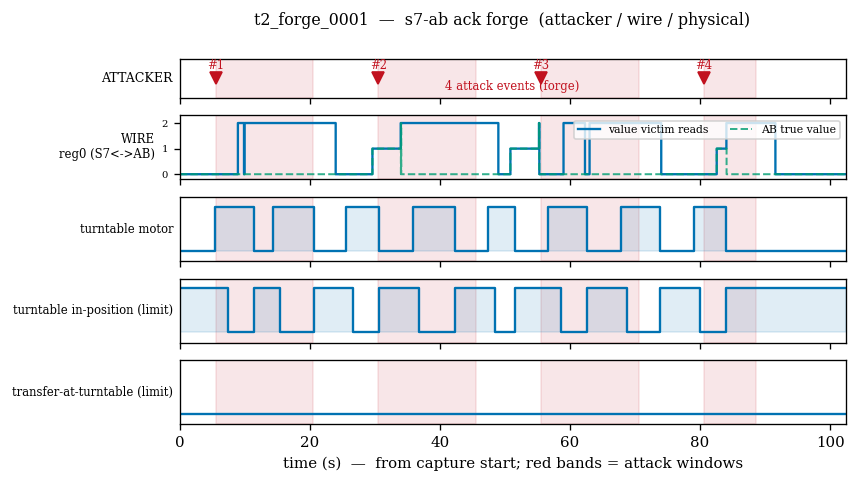

In [16]:
XEND=rel(float(pk[-1].time))
nrows=2+len(signals)
fig,axs=plt.subplots(nrows,1,figsize=(FULL_W,0.55*nrows+1.2),sharex=True,
                     gridspec_kw={"hspace":0.3,"height_ratios":[0.6,1]+[1]*len(signals)})
fig.suptitle(f"{EXPERIMENT_ID}  —  {PAIR} {TRANS} {ACTION}  (attacker / wire / physical)",fontsize=9.5)

# shade every attack window across all lanes
for a in axs:
    for (o,c) in onsets: a.axvspan(rel(o),rel(c),color=RED,alpha=0.10)
    a.set_yticks([]); a.set_xlim(0,XEND)

# ATTACKER lane
axs[0].set_ylabel("ATTACKER",fontsize=7.5,rotation=0,ha="right",va="center")
for i,(o,c) in enumerate(onsets,1):
    axs[0].plot([rel(o)],[0.5],"v",color=RED,ms=7)
    axs[0].text(rel(o),0.75,f"#{i}",color=RED,fontsize=7,ha="center")
axs[0].text(XEND*0.5,0.2,f"{len(onsets)} attack events ({ACTION})",fontsize=7,color=RED,ha="center")
axs[0].set_ylim(0,1)

# WIRE lane: register value the VICTIM reads (and AB-true for forge split-brain)
axs[1].set_ylabel(f"WIRE\n{REG_LABEL[REG]}",fontsize=7,rotation=0,ha="right",va="center")
if wire_client:
    xc=[p[0] for p in wire_client]; yc=[p[1] for p in wire_client]
    axs[1].step(xc,yc,where="post",color=BLUE,lw=1.4,label="value victim reads")
if ACTION in ("forge","replay") and wire_ab:
    xa=[p[0] for p in wire_ab]; ya=[p[1] for p in wire_ab]
    axs[1].step(xa,ya,where="post",color=GREEN,lw=1.2,ls="--",alpha=0.8,label="AB true value")
    axs[1].legend(fontsize=6.5,loc="upper right",ncol=2)
axs[1].set_ylim(-0.2,2.3); axs[1].set_yticks([0,1,2]); axs[1].set_yticklabels(["0","1","2"],fontsize=6)

# PHYSICAL lanes: handover signals in process order
for k,(tag,label) in enumerate(signals):
    ax=axs[2+k]; ax.set_ylabel(label,fontsize=7,rotation=0,ha="right",va="center")
    w=wave(tag)
    if w:
        xs,ys=w
        ax.step(xs,0.12+0.72*np.array(ys),where="post",color=BLUE,lw=1.4)
        ax.fill_between(xs,0.12,0.12+0.72*np.array(ys),step="post",color=BLUE,alpha=0.12)
    ax.set_ylim(-0.05,1.0)
axs[-1].set_xlabel("time (s)  —  from capture start; red bands = attack windows")
savename=f"attack_threeplane_{EXPERIMENT_ID}"
for ext in ("pdf","png"): fig.savefig(os.path.join(FIGDIR,f"{savename}.{ext}"))
print("saved:",savename); plt.show()

In [17]:
# --- Impact table: per-event STALL (not throughput; the line was reset) --
# For each attack window, how many physical transitions occurred on the handover
# signals (low = stalled), and did the register reach its signal value (handshake
# completed) during the window.
rows=[]
for i,(o,c) in enumerate(onsets,1):
    o_r,c_r=rel(o),rel(c)
    dur=c_r-o_r
    phys=ph[(ph.t>=o_r)&(ph.t<=c_r)]
    wc=[v for t,v in wire_client if o_r<=t<=c_r]
    reached=(2 in wc) if ACTION=="suppress" else None
    rows.append({"event":i,"window_s":round(dur,1),
                 "handover_transitions_in_window":len(phys),
                 "victim_saw_values":dict(pd.Series(wc).value_counts()) if wc else {},
                 "handshake_completed(reg->2)": (2 in wc)})
import pandas as pd
imp=pd.DataFrame(rows); display(imp)
imp.to_csv(os.path.join(FIGDIR,"impact_summary.csv"),index=False)
print("saved impact_summary.csv")
print("\\nNote: throughput is NOT the impact metric here (the line was reset between")
print("attacks, so ~6 pieces still completed). Impact = per-window STALL + handshake")
print("deception/suppression, shown above and in the figure.")

,event,window_s,handover_transitions_in_window,victim_saw_values,handshake_completed(reg->2)
0,1,15.0,5,"{2: 317, 0: 100}",True
1,2,15.0,6,"{2: 342, 1: 192}",True
2,3,15.0,6,"{2: 318, 0: 241}",True
3,4,8.0,2,"{2: 139, 0: 117, 1: 87}",True


saved impact_summary.csv
\nNote: throughput is NOT the impact metric here (the line was reset between
attacks, so ~6 pieces still completed). Impact = per-window STALL + handshake
deception/suppression, shown above and in the figure.
